In [16]:
TRAIN_DIR = "/home/lmalerba/projects/sdim_data_challenge/kaggle_challenge_sdi_cleaned/kaggle_challenge_sdi/data/pelgas_dataset/101141/individual_images"

/tmp/ipykernel_121628/2891773729.py:47: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  mask_rough = morphology.binary_dilation(mask_rough, morphology.disk(6))
/tmp/ipykernel_121628/2891773729.py:96: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  mask_plankton = morphology.binary_dilation(mask_fine, morphology.disk(3))
/tmp/ipykernel_121628/2891773729.py:47: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  mask_rough = morphology.binary_dilation(mask_rough, m

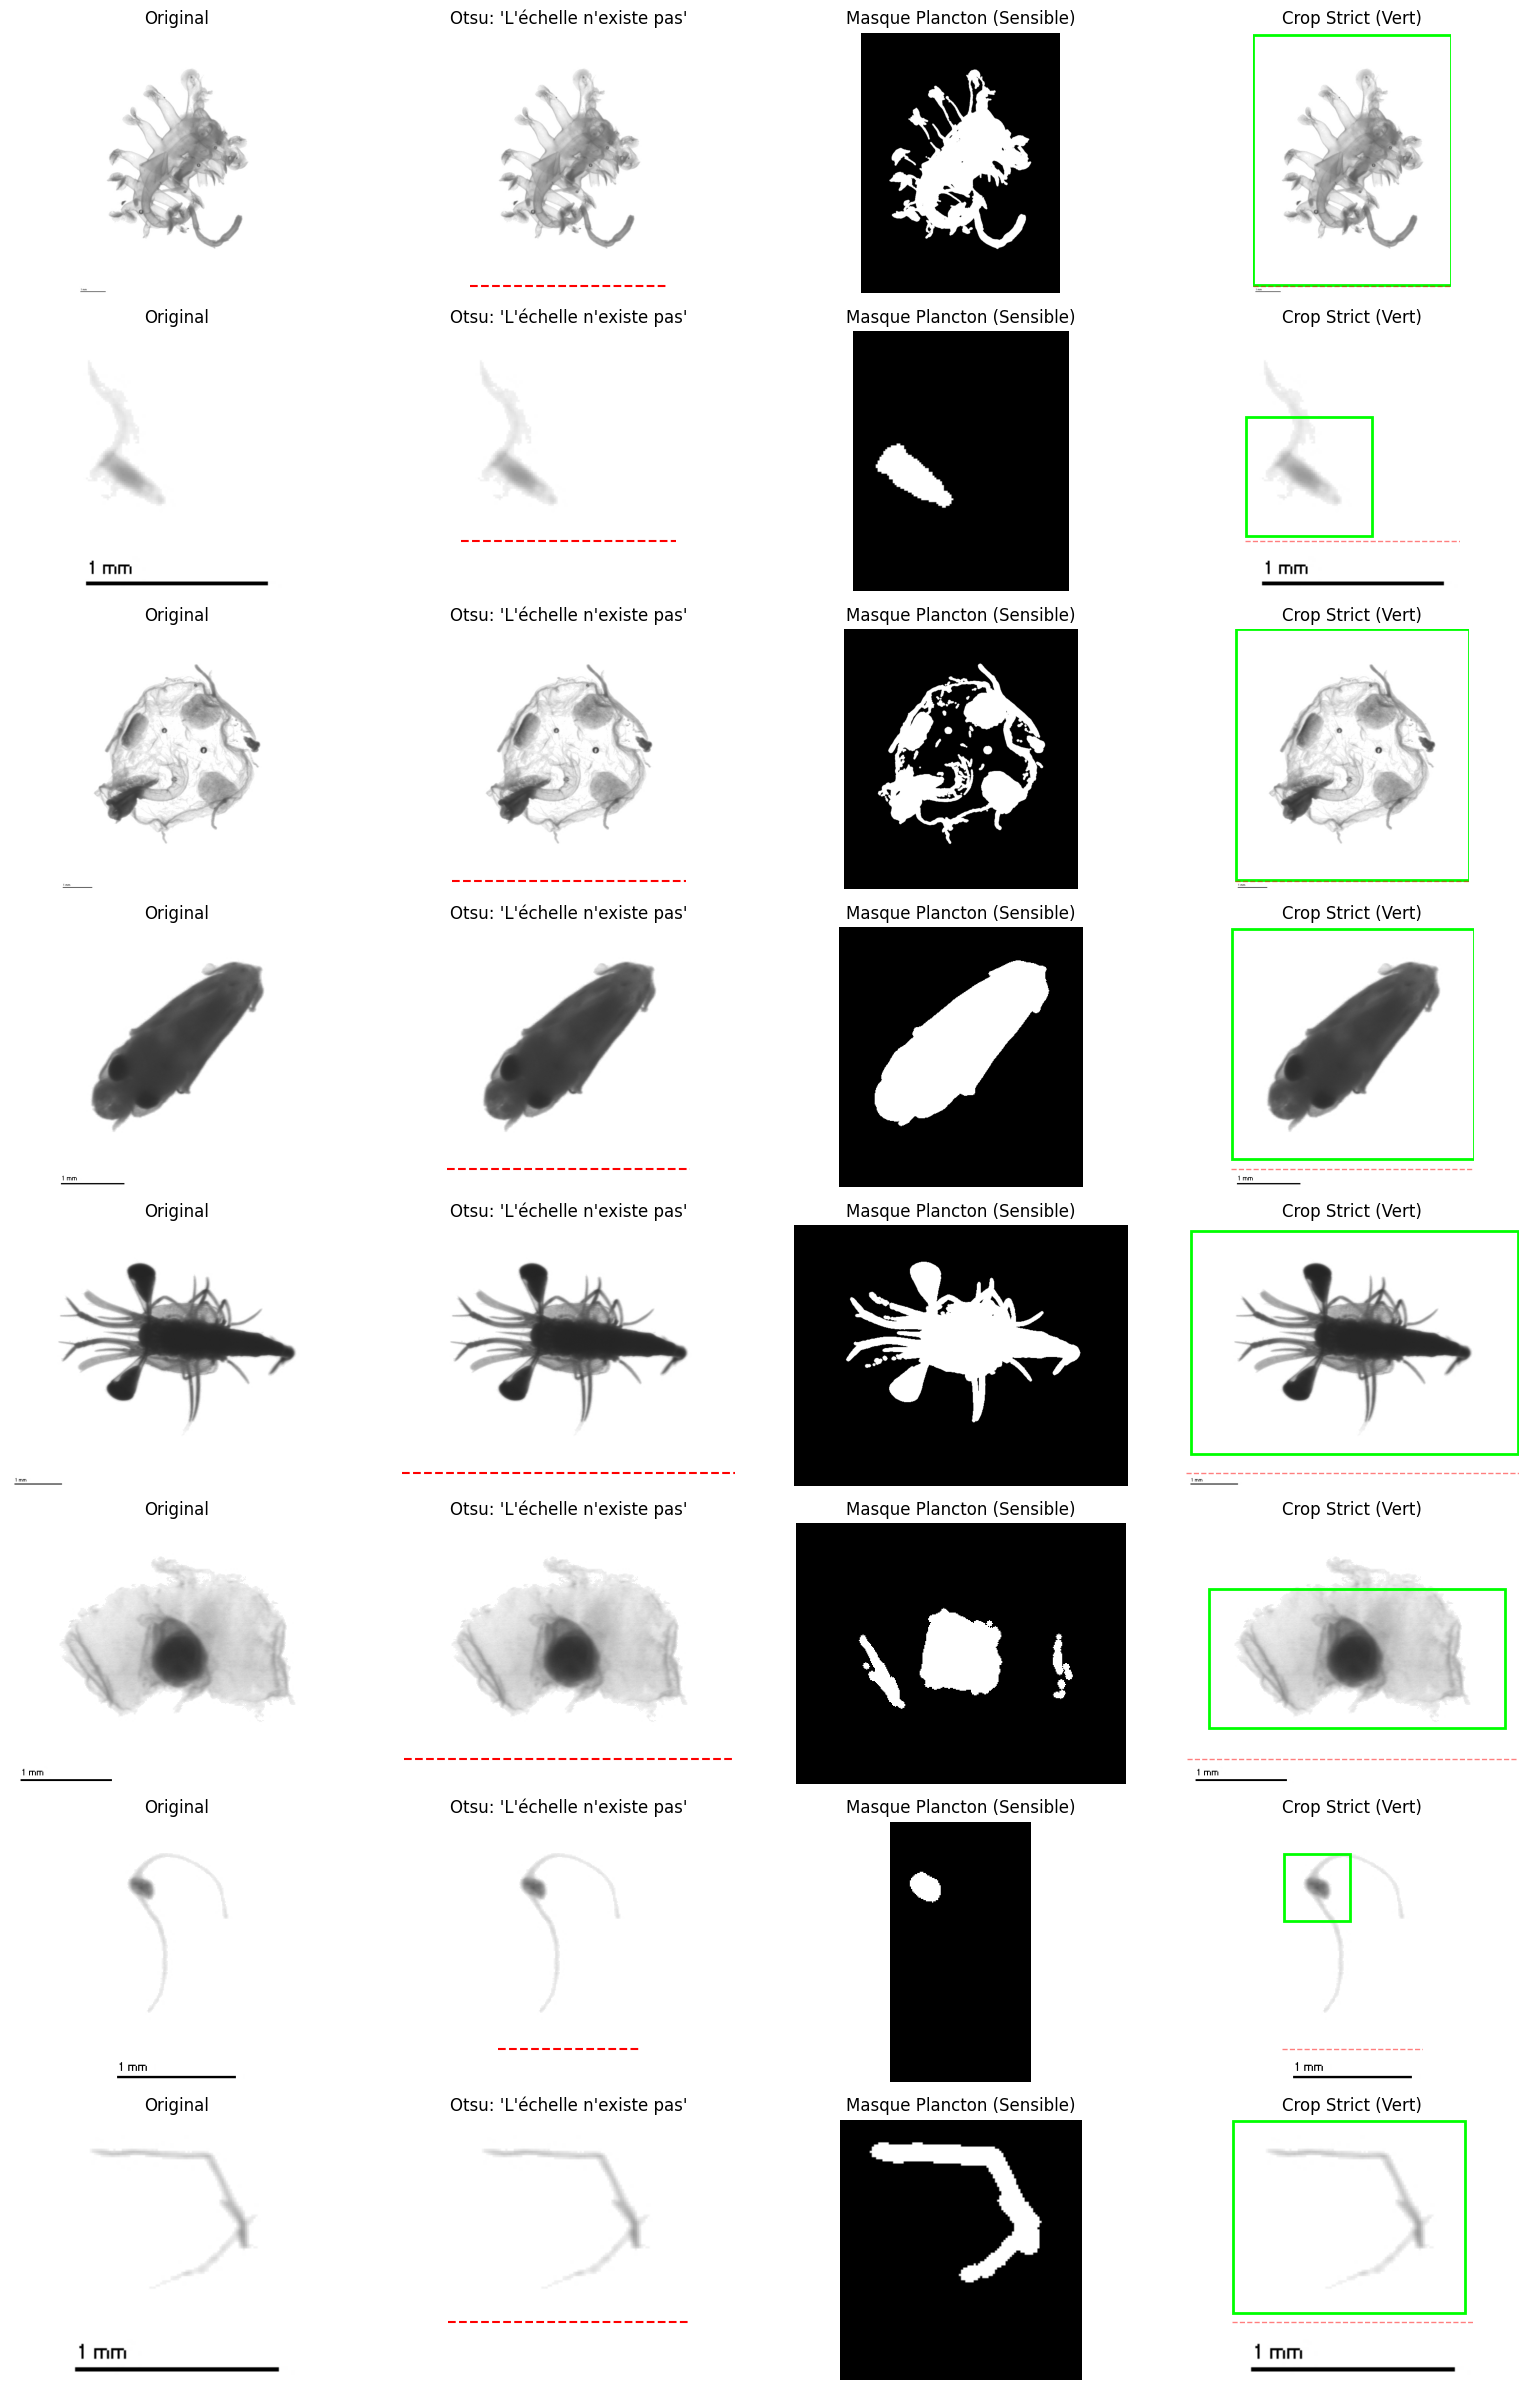

In [45]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from skimage import io, color, filters, measure, morphology

# === CONFIGURATION ===
PELGAS_DIR = TRAIN_DIR
N_SAMPLES = 8
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}

# === RÉGLAGES ===
MARGIN_RATIO = 0.2       # Marge 20%
BOTTOM_TOLERANCE = 20    # Zone du bas pour identifier l'échelle
SENSITIVITY = 100  # Plus besoin de forcer à 2.0, le Double Otsu fait le travail naturellement

def get_random_images_recursive(root_dir, n=10):
    root_path = Path(root_dir)
    subdirs = [p for p in root_path.iterdir() if p.is_dir()]
    if not subdirs: return []
    selected_images = []
    for _ in range(n * 2):
        rd = random.choice(subdirs)
        imgs = [p for p in rd.iterdir() if p.suffix.lower() in EXTENSIONS]
        if imgs: selected_images.append(str(random.choice(imgs)))
        if len(selected_images) >= n: break
    return selected_images

def smart_crop_double_otsu(image_path, margin_ratio=0.2):
    img = io.imread(image_path)
    if img.ndim == 3:
        gray = color.rgb2gray(img)
    else:
        gray = img
    
    h, w = gray.shape

    # --- ÉTAPE 1 : DÉTECTION DE L'ÉCHELLE (Otsu Brut) ---
    try:
        # Otsu classique sur toute l'image
        thresh_rough = filters.threshold_otsu(gray)
        mask_rough = gray < thresh_rough
        
        # On dilate pour bien souder le texte "1 m m"
        mask_rough = morphology.binary_dilation(mask_rough, morphology.disk(6))
        
        # On cherche l'objet qui touche le bas (l'échelle)
        lbl_rough = measure.label(mask_rough)
        regions_rough = measure.regionprops(lbl_rough)
        
        scale_top_limit = h # Par défaut, le bas de l'image
        scale_mask = np.zeros_like(mask_rough)

        found_scale = False
        for r in regions_rough:
            minr, minc, maxr, maxc = r.bbox
            # Si l'objet touche presque le bas
            if maxr >= h - BOTTOM_TOLERANCE:
                found_scale = True
                # On retient la position haute de l'échelle pour couper plus tard
                if minr < scale_top_limit:
                    scale_top_limit = minr
                # On marque cet objet comme étant l'échelle
                scale_mask[r.coords[:, 0], r.coords[:, 1]] = 1
                
    except:
        return img, np.zeros_like(gray), np.zeros_like(gray), None, h

    # Si on a trouvé une échelle, on remonte un peu la limite de sécurité (ex: 5 pixels au dessus)
    if found_scale:
        scale_top_limit = max(0, scale_top_limit - 5)

    # --- ÉTAPE 2 : DÉTECTION DU PLANCTON (Image Nettoyée) ---
    
    # On crée une image "virtuelle" où l'échelle est effacée (remplacée par du blanc/fond)
    # Cela empêche l'échelle noire de fausser l'histogramme d'Otsu
    gray_clean = gray.copy()
    # On met à 1.0 (blanc) tout ce qui est sous la ligne de flottaison de l'échelle
    # C'est plus radical et sûr que d'utiliser le masque : on vire tout le bas.
    gray_clean[scale_top_limit:h, :] = 1.0 

    try:
        # Otsu sur l'image SANS l'échelle noire
        # L'algo va maintenant se concentrer sur la différence Blanc vs Gris Clair
        thresh_fine = filters.threshold_otsu(gray_clean)
        mask_fine = gray_clean < thresh_fine # (ou gray < thresh_fine & range usage)
    except:
         mask_fine = np.zeros_like(gray, dtype=bool)

    # Inversion si nécessaire (si fond noir...)
    if np.sum(mask_fine) > mask_fine.size * 0.5: mask_fine = ~mask_fine

    # Petit nettoyage (dilatation légère pour recoller le plancton)
    mask_plankton = morphology.binary_dilation(mask_fine, morphology.disk(3))

    # --- ÉTAPE 3 : CROP INTELLIGENT AVEC PLAFOND ---
    coords = np.argwhere(mask_plankton)
    
    bbox = None
    if coords.size > 0:
        minr, minc = coords.min(axis=0)
        maxr, maxc = coords.max(axis=0)
        
        # Calcul marges dynamiques
        h_box, w_box = maxr - minr, maxc - minc
        pad_h = int(h_box * margin_ratio)
        pad_w = int(w_box * margin_ratio)
        pad_h = max(pad_h, 15) # Minimum vital
        pad_w = max(pad_w, 15)

        safe_minr = max(0, minr - pad_h)
        safe_minc = max(0, minc - pad_w)
        
        # ICI : La contrainte stricte.
        # Le bas du crop ne doit JAMAIS dépasser le haut de l'échelle détectée
        safe_maxr = min(scale_top_limit, maxr + pad_h) 
        safe_maxc = min(w, maxc + pad_w)
        
        # Sécurité anti-bug (si min > max)
        if safe_maxr > safe_minr and safe_maxc > safe_minc:
            bbox = (safe_minr, safe_minc, safe_maxr, safe_maxc)

    # On retourne aussi scale_top_limit pour l'afficher en rouge
    return img, gray_clean, mask_plankton, bbox, scale_top_limit

# === VISUALISATION ===
samples_paths = get_random_images_recursive(PELGAS_DIR, N_SAMPLES)

if samples_paths:
    fig, axes = plt.subplots(len(samples_paths), 4, figsize=(16, 3 * len(samples_paths)))
    if len(samples_paths) == 1: axes = [axes] 

    for i, img_path in enumerate(samples_paths):
        original, img_cleaned_phantom, mask_final, bbox, limit_line = smart_crop_double_otsu(img_path, margin_ratio=MARGIN_RATIO)
        
        # 1. Originale
        axes[i][0].imshow(original, cmap='gray' if original.ndim==2 else None)
        axes[i][0].set_title("Original")
        axes[i][0].axis('off')

        # 2. L'image "mentale" vue par le 2eme Otsu
        axes[i][1].imshow(img_cleaned_phantom, cmap='gray', vmin=0, vmax=1)
        axes[i][1].axhline(y=limit_line, color='red', linestyle='--')
        axes[i][1].set_title("Otsu: 'L'échelle n'existe pas'")
        axes[i][1].axis('off')

        # 3. Le Masque résultant
        axes[i][2].imshow(mask_final, cmap='gray')
        axes[i][2].set_title("Masque Plancton (Sensible)")
        axes[i][2].axis('off')

        # 4. Résultat Final
        axes[i][3].imshow(original, cmap='gray' if original.ndim==2 else None)
        
        # On dessine la ligne rouge qui était la limite interdite
        axes[i][3].axhline(y=limit_line, color='red', linestyle='--', linewidth=1, alpha=0.5)

        if bbox:
            minr, minc, maxr, maxc = bbox
            rect = patches.Rectangle((minc, minr), maxc - minc, maxr - minr,
                                     linewidth=2, edgecolor='#00FF00', facecolor='none')
            axes[i][3].add_patch(rect)
            axes[i][3].set_title("Crop Strict (Vert)")
        else:
             axes[i][3].set_title("Vide / Echec")
        
        axes[i][3].axis('off')

    plt.tight_layout()
    plt.show()


/tmp/ipykernel_121628/4152136238.py:57: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  mask_rough = morphology.binary_dilation(mask_rough, morphology.disk(6))
/tmp/ipykernel_121628/4152136238.py:95: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  mask_plankton = morphology.binary_dilation(mask_fine, morphology.disk(2))
/tmp/ipykernel_121628/4152136238.py:57: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  mask_rough = morphology.binary_dilation(mask_rough, m

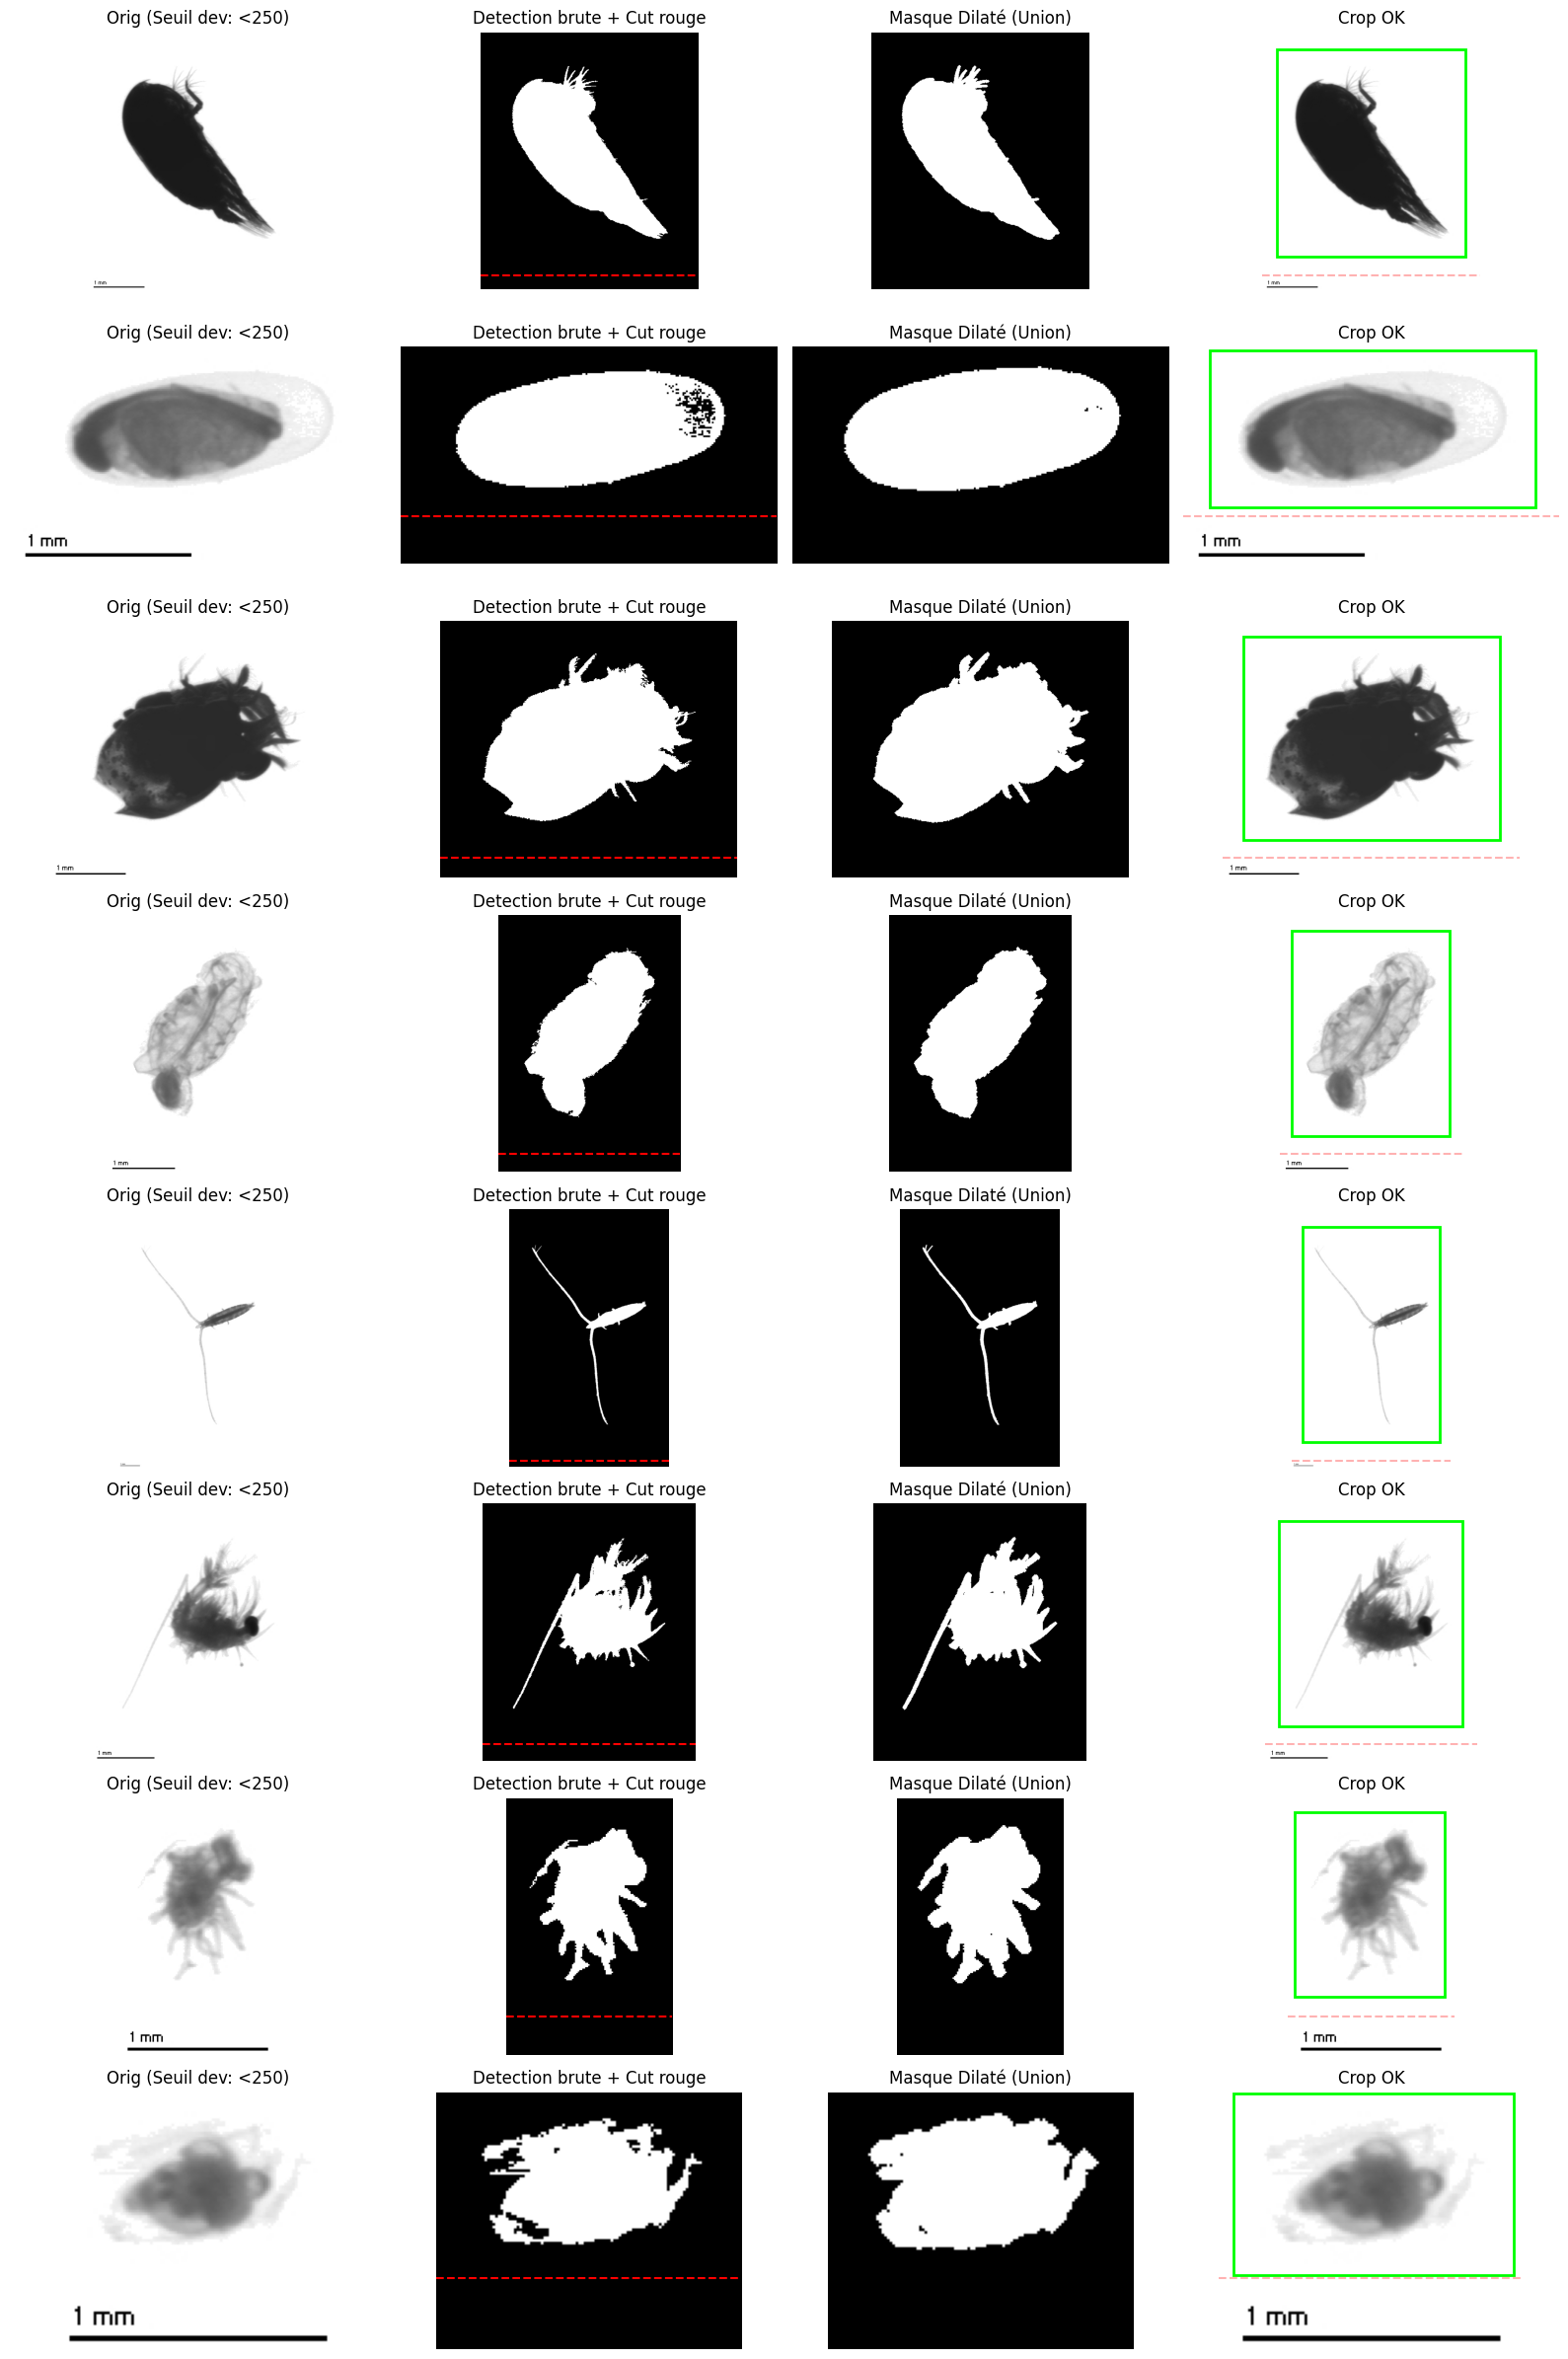

In [46]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from skimage import io, color, filters, measure, morphology

# === CONFIGURATION ===
PELGAS_DIR = TRAIN_DIR
N_SAMPLES = 8
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}

# === NOUVEAUX RÉGLAGES ===
MARGIN_RATIO = 0.10
BOTTOM_TOLERANCE = 20    

# C'est LE paramètre magique maintenant.
# Plus il est bas, plus il capture le transparent.
# 5 signifie : "Si un pixel est 5 niveaux de gris plus sombre que le fond, je le prends."
# Valeurs conseillées : entre 3 (très agressif) et 15 (plus doux).
NOISE_TOLERANCE = 5 

def get_random_images_recursive(root_dir, n=10):
    root_path = Path(root_dir)
    subdirs = [p for p in root_path.iterdir() if p.is_dir()]
    if not subdirs: return []
    try:
        selected_images = []
        possible_dirs = subdirs if subdirs else [root_path]
        for _ in range(n * 3):
            rd = random.choice(possible_dirs)
            imgs = [p for p in rd.iterdir() if p.suffix.lower() in EXTENSIONS]
            if imgs: selected_images.append(str(random.choice(imgs)))
            if len(selected_images) >= n: break
        return selected_images
    except: return []

def smart_crop_background_deviation(image_path, margin_ratio=0.2, noise_tolerance=5):
    img = io.imread(image_path)
    if img.ndim == 3:
        gray = color.rgb2gray(img)
        # Convert to 0-255 uint8 for consistent math if currently float
        if gray.max() <= 1.0: gray = (gray * 255).astype(np.uint8)
    else:
        gray = img
        if gray.dtype != np.uint8 and gray.max() <= 1.0:
            gray = (gray * 255).astype(np.uint8)
    
    h, w = gray.shape

    # --- ÉTAPE 1 : DÉTECTION DE L'ÉCHELLE (Inchangé, ça marche bien) ---
    # Pour l'échelle (noir profond), Otsu reste très bon
    try:
        thresh_rough = filters.threshold_otsu(gray)
        mask_rough = gray < thresh_rough
        mask_rough = morphology.binary_dilation(mask_rough, morphology.disk(6))
        lbl_rough = measure.label(mask_rough)
        regions_rough = measure.regionprops(lbl_rough)
        
        scale_top_limit = h 
        found_scale = False
        
        for r in regions_rough:
            minr, minc, maxr, maxc = r.bbox
            if maxr >= h - BOTTOM_TOLERANCE:
                found_scale = True
                if minr < scale_top_limit: scale_top_limit = minr

        if found_scale: scale_top_limit = max(0, scale_top_limit - 5)

    except:
        scale_top_limit = h

    # --- ÉTAPE 2 : DÉTECTION PAR ÉCART AU FOND (La nouveauté) ---
    
    # 1. On estime la couleur du fond. 
    # Hypothèse : Le fond est majoritaire, c'est la médiane ou le mode.
    # Pour éviter d'être biaisé par l'échelle noire, on regarde le haut de l'image.
    bg_sample = gray[0:h//2, :]
    bg_value = np.median(bg_sample) # Probablement environ 250-255
    
    # 2. On calcule le seuil fixe
    # Tout ce qui est < (Fond - Tolerance) est un objet
    threshold_value = bg_value - noise_tolerance
    
    # 3. Création du masque
    # On ignore directement la zone de l'échelle en bas
    mask_fine = (gray < threshold_value)
    mask_fine[scale_top_limit:h, :] = False # Force le bas à False (supprime l'échelle)

    # Petit nettoyage des poussières isolées (optionnel)
    # mask_fine = morphology.binary_opening(mask_fine, morphology.disk(1))
    # Dilatation pour souder les parties transparentes disjointes
    mask_plankton = morphology.binary_dilation(mask_fine, morphology.disk(2))

    # --- ÉTAPE 3 : CROP & RETURN ---
    coords = np.argwhere(mask_plankton)
    bbox = None
    pad_h_val = 0
    
    if coords.size > 0:
        minr, minc = coords.min(axis=0)
        maxr, maxc = coords.max(axis=0)
        
        h_box, w_box = maxr - minr, maxc - minc
        pad_h = int(h_box * margin_ratio)
        pad_w = int(w_box * margin_ratio)
        pad_h = max(pad_h, 10)
        pad_w = max(pad_w, 10)
        pad_h_val = pad_h

        safe_minr = max(0, minr - pad_h)
        safe_minc = max(0, minc - pad_w)
        # On ne dépasse jamais la scale_top_limit
        safe_maxr = min(scale_top_limit, maxr + pad_h)
        safe_maxc = min(w, maxc + pad_w)
        
        if safe_maxr > safe_minr and safe_maxc > safe_minc:
            bbox = (safe_minr, safe_minc, safe_maxr, safe_maxc)

    return img, mask_fine, mask_plankton, bbox, scale_top_limit, threshold_value

# === VISUALISATION ===
samples_paths = get_random_images_recursive(PELGAS_DIR, N_SAMPLES)

if samples_paths:
    fig, axes = plt.subplots(len(samples_paths), 4, figsize=(16, 3 * len(samples_paths)))
    if len(samples_paths) == 1: axes = [axes] 

    for i, img_path in enumerate(samples_paths):
        original, mask_raw, mask_final, bbox, limit_line, thresh_used = smart_crop_background_deviation(
            img_path, margin_ratio=MARGIN_RATIO, noise_tolerance=NOISE_TOLERANCE
        )
        
        # 1. Originale
        axes[i][0].imshow(original, cmap='gray' if original.ndim==2 else None)
        axes[i][0].set_title(f"Orig (Seuil dev: <{int(thresh_used)})")
        axes[i][0].axis('off')

        # 2. Masque Brut (Deviation pure)
        axes[i][1].imshow(mask_raw, cmap='gray')
        # On dessine la ligne qui coupe l'échelle
        axes[i][1].axhline(y=limit_line, color='red', linestyle='--')
        axes[i][1].set_title("Detection brute + Cut rouge")
        axes[i][1].axis('off')

        # 3. Masque Final (Dilaté)
        axes[i][2].imshow(mask_final, cmap='gray')
        axes[i][2].set_title("Masque Dilaté (Union)")
        axes[i][2].axis('off')

        # 4. Crop
        axes[i][3].imshow(original, cmap='gray' if original.ndim==2 else None)
        axes[i][3].axhline(y=limit_line, color='red', linestyle='--', alpha=0.3)
        
        if bbox:
            minr, minc, maxr, maxc = bbox
            rect = patches.Rectangle((minc, minr), maxc - minc, maxr - minr,
                                     linewidth=2, edgecolor='#00FF00', facecolor='none')
            axes[i][3].add_patch(rect)
            axes[i][3].set_title("Crop OK")
        else:
            axes[i][3].set_title("Rien détecté")
        axes[i][3].axis('off')

    plt.tight_layout()
    plt.show()
